# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Rendeiro 2020's CLL malignant manifold is **non-branching**: the three embryonic developmental
signatures (gastrulation / posterior somitogenesis / neural crest) fall onto a **single axis** rather
than resolving into two competing arms. A PPT *tree* over this compact near-round cloud fabricates
**spurious forks** (fork count climbs with node count — the branching machinery inventing bifurcations in
one blob); an ElPiGraph *curve* returns a clean, fold-free 2-tip backbone. We therefore fit a **curve**,
keep every cell on its original joint embedding (no re-embedding of a linear compartment), root at the
**Gast/pSom-high developmental origin** (Crest is *late*), and check the curve for folds using node
geometry independent of the tested embedding. Deliverables: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
from scipy.stats import spearmanr
import scipy.spatial.distance as ssd
import matplotlib.pyplot as plt
sc.settings.verbosity = 0; np.random.seed(0)

In [2]:
name = os.path.basename(os.getcwd()); category = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*(['..'] * 6))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
print('loaded processed.h5ad:', adata.shape)

loaded processed.h5ad: (18314, 14889)


### Scope decision — whole manifold (proliferation diffuse, axis developmental)
Confirmed in 01: single Leiden compartment, proliferation diffuse, developmental gradient reproduces
within every clone and does not track cell cycle. There is no proliferative lobe to scope out, so the
whole malignant manifold is carried into the trajectory.

In [3]:
cyc = (adata.obs.phase != 'G1').astype(float).values
print('developmental axis vs cell cycle:',
      ' '.join(f'corr({m}_sm,cyc)={np.corrcoef(adata.obs[m+"_sm"],cyc)[0,1]:+.3f}' for m in ['Gast','pSom','Crest']))
print('=> not a cell-cycle confound; keep whole manifold (no scoping).')

developmental axis vs cell cycle: corr(Gast_sm,cyc)=+0.016 corr(pSom_sm,cyc)=-0.010 corr(Crest_sm,cyc)=-0.018
=> not a cell-cycle confound; keep whole manifold (no scoping).


### Topology probe — PPT tree forks vs principal curve
Fit a PPT *tree* at increasing node counts and count tips/forks; then an ElPiGraph *curve*. A real
bifurcation gives a **stable** fork; a single blob gives forks whose number **grows with node count**
(overfitting). The curve's fold is checked by the node **self-approach ratio** = min distance between
graph-non-adjacent nodes / median edge length (>1 = fold-free) — geometry of the fitted graph, not the
neighbour structure of the embedding being tested.

In [4]:
for N in [100, 150, 200]:
    b = adata.copy()
    scf.tl.tree(b, method='ppt', Nodes=N, ppt_lambda=2000, ppt_sigma=0.5, use_rep='X_umap', seed=1, plot=False)
    B = b.uns['graph']['B']; deg = B.sum(0)
    print(f'PPT tree N={N}: {int((deg==1).sum())} tips, {int((deg>2).sum())} forks (spurious -> not a real bifurcation)')
def selfapproach(ad):
    F = ad.uns['graph']['F']; B = ad.uns['graph']['B']
    D = ssd.squareform(ssd.pdist(F.T)); adj = B > 0
    edge = D[adj].mean(); Dn = D.copy(); np.fill_diagonal(Dn, np.inf); Dn[adj] = np.inf
    return Dn.min() / edge
for N in [15, 20, 30]:
    b = adata.copy(); scf.tl.curve(b, Nodes=N, use_rep='X_umap', seed=1, plot=False)
    B = b.uns['graph']['B']; deg = B.sum(0)
    print(f'curve N={N}: {int((deg==1).sum())} tips, {int((deg>2).sum())} forks | self-approach {selfapproach(b):.2f} (>1 fold-free)')
print('chosen: curve N=20 (2 tips, 0 forks, fold-free); PPT tree forks are unstable/spurious.')

inferring a principal tree --> parameters used 
    100 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:  22%|##2       | 11/50 [00:01<00:03, 10.08it/s]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
PPT tree N=100: 6 tips, 4 forks (spurious -> not a real bifurcation)
inferring a principal tree --> parameters used 
    150 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:  28%|##8       | 14/50 [00:00<00:01, 26.11it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] co

### Fit the committed curve and derive the root (data-driven)
Fit `curve` N=20. The root is the tip where Gast is highest and Crest lowest — the developmental origin
(Gast/pSom early, Crest late; never root at Crest or a proliferation state). Pseudotime then flows toward
the neural-crest terminus.

In [5]:
scf.tl.curve(adata, Nodes=20, use_rep='X_umap', seed=1, plot=False)
B = adata.uns['graph']['B']; deg = B.sum(0); tips = np.where(deg == 1)[0]; R = adata.obsm['X_R']
tv = {}
for t in tips:
    w = R[:, t]
    tv[int(t)] = (np.average(adata.obs.Gast_sm, weights=w), np.average(adata.obs.pSom_sm, weights=w),
                  np.average(adata.obs.Crest_sm, weights=w))
    print(f'tip {t}: Gast_sm {tv[int(t)][0]:+.4f} pSom_sm {tv[int(t)][1]:+.4f} Crest_sm {tv[int(t)][2]:+.4f}')
root = max(tips, key=lambda t: tv[int(t)][0] - tv[int(t)][2])
print('derived root tip =', int(root), '(max Gast-Crest = developmental origin)')
scf.tl.root(adata, int(root)); scf.tl.pseudotime(adata, n_jobs=4)
t = adata.obs['t'].values
print('pseudotime range %.2f -> %.2f' % (t.min(), t.max()))
for nm in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, _ = spearmanr(t, adata.obs[nm]); print(f'  gradient {nm}: Spearman rho = {rho:+.3f}')

inferring a principal curve --> parameters used 
    20 principal points, mu = 0.1, lambda = 0.01
    finished (0:00:02) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
tip 0: Gast_sm -0.0196 pSom_sm +0.0070 Crest_sm +0.0083
tip 2: Gast_sm -0.0172 pSom_sm +0.0070 Crest_sm +0.0067
derived root tip = 2 (max Gast-Crest = developmental origin)
node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:05) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree a

### Reorient to house style (pseudotime left -> right)
Fix the sign of the house orientation (derived in 01) so low pseudotime sits on the left. Discrete sign
choice on the already-rotated `X_umap_lin` — no new rotation, no re-embedding.

In [6]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:, 0], t)[0, 1])
if r < 0:
    adata.obsm['X_umap_lin'][:, 0] = -adata.obsm['X_umap_lin'][:, 0]
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:, 0], t)[0, 1])
print(f'house orientation corr(x_lin, pseudotime) = {r:+.2f}')

house orientation corr(x_lin, pseudotime) = +0.58


### Save manifold + trajectory figure (deliverable) — house style `(3.5,1.5)`, cividis

saved manifold.h5ad + manifold.pdf


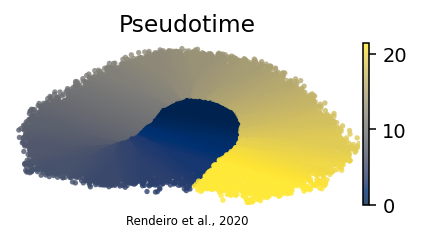

In [7]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['graph']['F']).T}
adata.write(os.path.join(pth_in, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf')